Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Image 01.png: 1 pessoa(s) identificada(s)


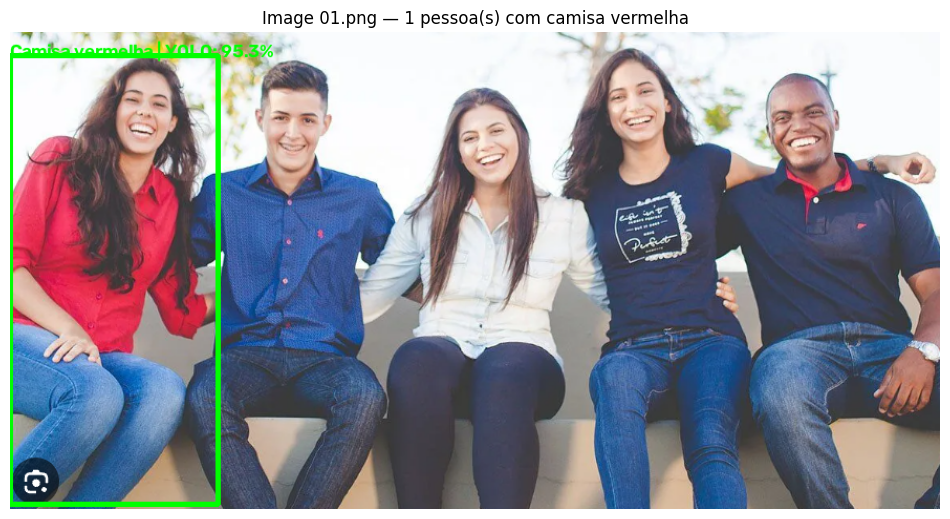

Image 02.png: 2 pessoa(s) identificada(s)


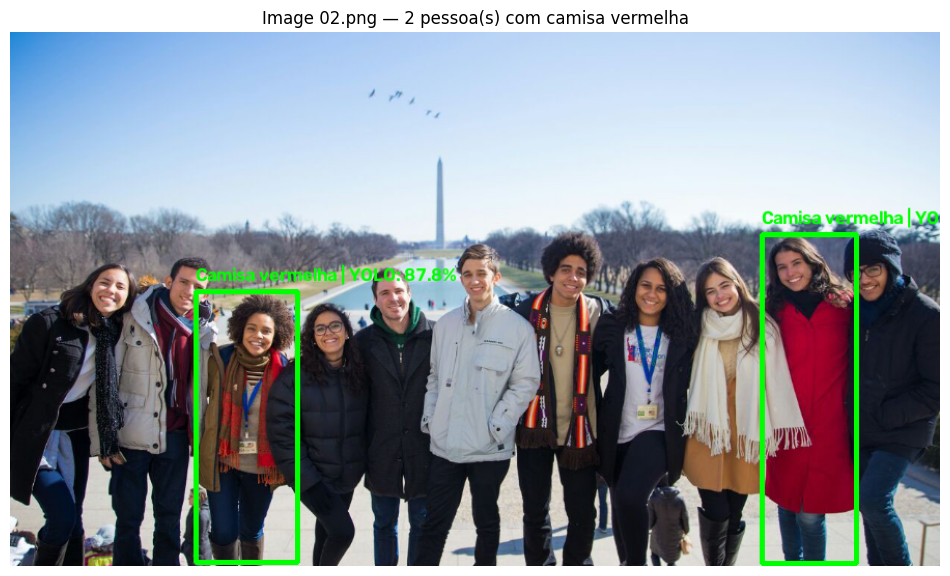

Image 03.png: 1 pessoa(s) identificada(s)


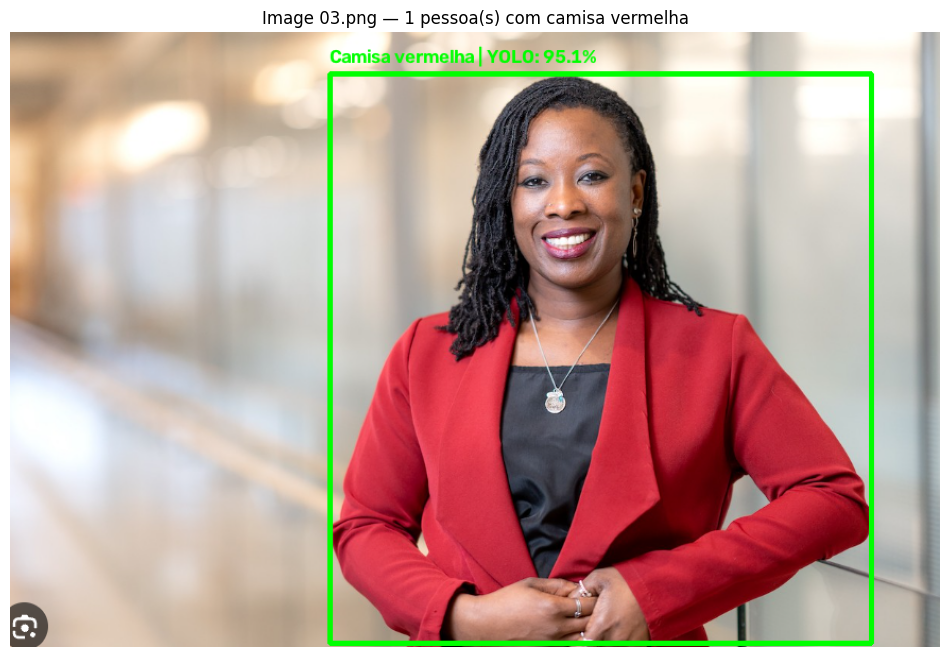

Image 04.png: 2 pessoa(s) identificada(s)


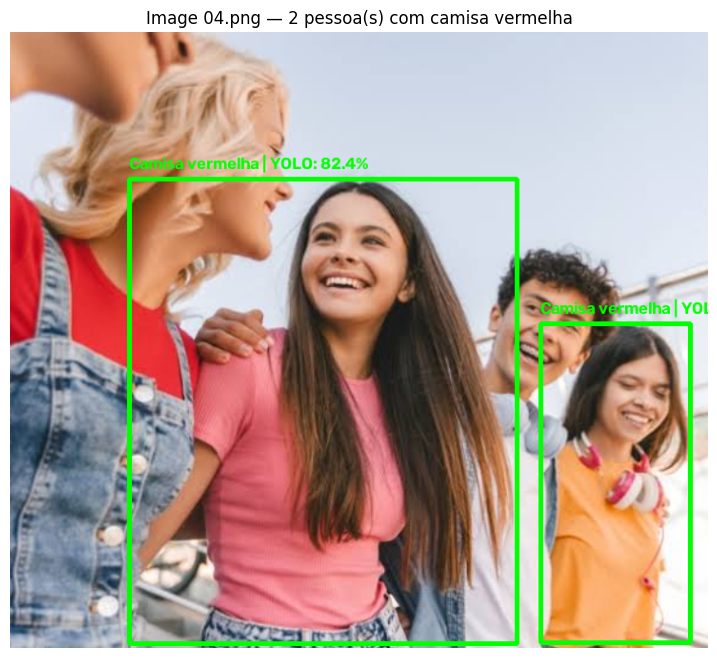

Image 05.png: 3 pessoa(s) identificada(s)


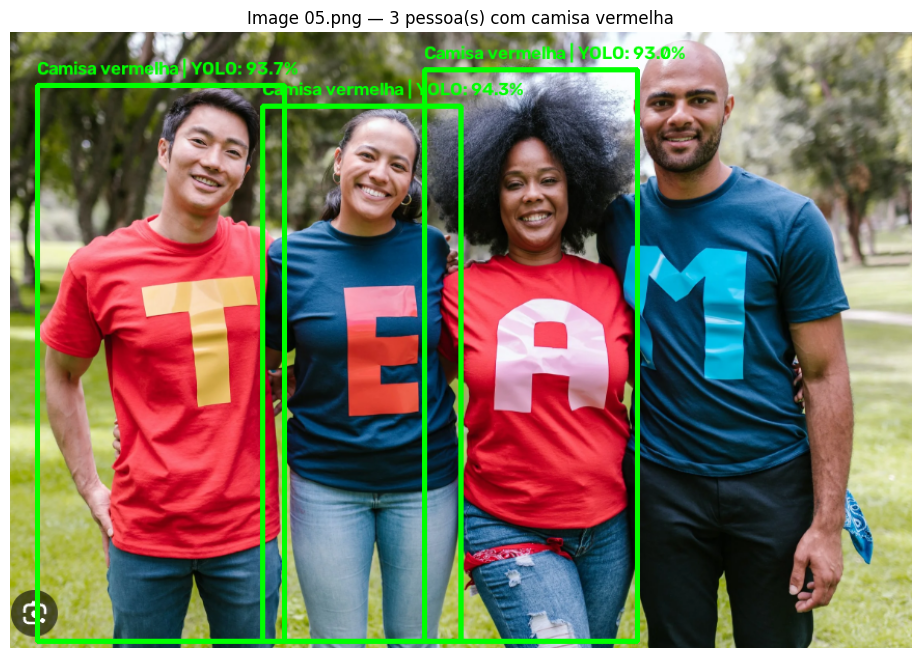

In [ ]:

!pip install -q -U ultralytics opencv-python-headless

from ultralytics import YOLO
from google.colab import drive
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Conectar ao Google Drive
drive.mount('/content/drive')

# Pasta das imagens
pasta = Path('/content/drive/MyDrive/Trabalho Visão Computacional')

# Carregar modelo de detecção de pessoas
model = YOLO("yolov8m.pt")

# Processar Image 01 até Image 08
for numero in range(1, 9):

    extensoes = [".jpg", ".jpeg", ".png", ".webp"]

    arquivo = next(
        (
            pasta / f"Image {numero:02d}{ext}"
            for ext in extensoes
            if (pasta / f"Image {numero:02d}{ext}").exists()
        ),
        None
    )

    if arquivo is None:
        print(f"Image {numero:02d}: arquivo não encontrado.")
        continue

    imagem = cv2.imread(str(arquivo))

    if imagem is None:
        print(f"Erro ao abrir {arquivo.name}")
        continue

    saida = imagem.copy()
    pessoas_vermelhas = 0

    # Detectar pessoas com confiança mínima de 60%
    resultado = model.predict(
        source=imagem,
        classes=[0],
        conf=0.60,
        imgsz=960,
        verbose=False
    )[0]

    for box in resultado.boxes:

        confianca = float(box.conf[0])

        # Garantir confiança estritamente superior a 60%
        if confianca <= 0.60:
            continue

        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())

        largura = x2 - x1
        altura = y2 - y1

        if largura < 10 or altura < 20:
            continue

        # Recortar a região aproximada da camisa
        topo = max(0, y1 + int(altura * 0.18))
        base = min(imagem.shape[0], y1 + int(altura * 0.60))
        esquerda = max(0, x1 + int(largura * 0.15))
        direita = min(imagem.shape[1], x2 - int(largura * 0.15))

        camisa = imagem[topo:base, esquerda:direita]

        if camisa.size == 0:
            continue

        # Converter para HSV e detectar tons vermelhos
        hsv = cv2.cvtColor(camisa, cv2.COLOR_BGR2HSV)

        vermelho1 = cv2.inRange(
            hsv,
            np.array([0, 70, 50]),
            np.array([10, 255, 255])
        )

        vermelho2 = cv2.inRange(
            hsv,
            np.array([170, 70, 50]),
            np.array([180, 255, 255])
        )

        mascara = cv2.bitwise_or(vermelho1, vermelho2)

        proporcao_vermelha = (
            np.count_nonzero(mascara) / mascara.size
        )

        # Exibir apenas pessoas com região predominantemente vermelha
        if proporcao_vermelha >= 0.20:

            pessoas_vermelhas += 1

            cv2.rectangle(
                saida,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                3
            )

            texto = (
                f"Camisa vermelha | YOLO: {confianca:.1%}"
            )

            cv2.putText(
                saida,
                texto,
                (x1, max(y1 - 10, 25)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (0, 255, 0),
                2
            )

    print(
        f"{arquivo.name}: "
        f"{pessoas_vermelhas} pessoa(s) identificada(s)"
    )

    # Exibir resultado
    plt.figure(figsize=(12, 8))
    plt.imshow(cv2.cvtColor(saida, cv2.COLOR_BGR2RGB))
    plt.title(
        f"{arquivo.name} — "
        f"{pessoas_vermelhas} pessoa(s) com camisa vermelha"
    )
    plt.axis("off")
    plt.show()

    # Salvar na mesma pasta
    caminho_saida = pasta / f"Resultado_Image_{numero:02d}.jpg"
    cv2.imwrite(str(caminho_saida), saida)

print("\nProcessamento concluído!")
